<a href="https://colab.research.google.com/github/Anagha-code12/AI-ML-Project/blob/main/AI_ML_Part_2_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q xgboost joblib

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Chemicaldata.zip to Chemicaldata.zip


In [ ]:
import zipfile
import os

zip_name = list(uploaded.keys())[0]

extract_path = "/content/data"

with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction Completed")

Extraction Completed


In [ ]:
import pandas as pd

csv_file = None

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.endswith(".csv"):
            csv_file = os.path.join(root, file)

print(csv_file)

df = pd.read_csv(csv_file)

df.head()

/content/data/chemical_process_timeseries.csv


,timestamp,operating_regime,reactor_id,ambient_temp_effect,reactor_temp,reactor_pressure,feed_flow_rate,coolant_flow_rate,agitator_speed_rpm,reaction_rate,...,selectivity,yield_pct,vibration_rms,motor_current,power_consumption_kw,temp_setpoint,pressure_setpoint,fault_type,efficiency_loss_pct,time_to_fault_min
0,2024-01-01 00:00:00,A,A_R1,0.000000,181.135558,15.791013,101.108882,79.154645,305.779931,0.724542,...,91.927424,82.032893,1.470297,45.882315,41.294083,180.0,12.0,0,0.0,NaN
1,2024-01-01 00:01:00,A,A_R1,0.000485,182.249820,15.706975,98.932369,NaN,302.283603,0.728999,...,91.581466,81.301503,1.425847,46.755905,42.080314,180.0,12.0,0,0.0,NaN
2,2024-01-01 00:02:00,A,A_R1,0.000970,183.129737,15.593397,99.792219,80.593736,305.814440,0.732519,...,91.895056,82.006626,1.448190,NaN,NaN,NaN,12.0,0,NaN,NaN
3,2024-01-01 00:03:00,A,A_R1,0.001454,183.020987,15.527333,99.854222,80.190444,304.436123,0.732084,...,91.544885,81.562261,1.473448,45.862171,41.275954,180.0,12.0,0,0.0,NaN
4,2024-01-01 00:04:00,A,A_R1,0.001939,183.077096,NaN,99.302349,78.571707,304.811418,0.732308,...,92.258005,82.411124,1.523491,46.880227,42.192204,180.0,12.0,0,NaN,NaN


In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

for col in df.select_dtypes(include='object').columns:
    df[col] = encoder.fit_transform(df[col])

df['timestamp'] = pd.to_datetime(df['timestamp'])

df['Year'] = df['timestamp'].dt.year
df['Month'] = df['timestamp'].dt.month
df['Day'] = df['timestamp'].dt.day
df['Hour'] = df['timestamp'].dt.hour

df.drop('timestamp', axis=1, inplace=True)

df.head()

,operating_regime,reactor_id,ambient_temp_effect,reactor_temp,reactor_pressure,feed_flow_rate,coolant_flow_rate,agitator_speed_rpm,reaction_rate,conversion_rate,...,power_consumption_kw,temp_setpoint,pressure_setpoint,fault_type,efficiency_loss_pct,time_to_fault_min,Year,Month,Day,Hour
0,0,0,0.000000,181.135558,15.791013,101.108882,79.154645,305.779931,0.724542,99.151760,...,41.294083,180.0,12.0,0,0.0,NaN,1970,1,1,0
1,0,0,0.000485,182.249820,15.706975,98.932369,NaN,302.283603,0.728999,98.638957,...,42.080314,180.0,12.0,0,0.0,NaN,1970,1,1,0
2,0,0,0.000970,183.129737,15.593397,99.792219,80.593736,305.814440,0.732519,99.154925,...,NaN,NaN,12.0,0,NaN,NaN,1970,1,1,0
3,0,0,0.001454,183.020987,15.527333,99.854222,80.190444,304.436123,0.732084,98.994864,...,41.275954,180.0,12.0,0,0.0,NaN,1970,1,1,0
4,0,0,0.001939,183.077096,NaN,99.302349,78.571707,304.811418,0.732308,99.252000,...,42.192204,180.0,12.0,0,NaN,NaN,1970,1,1,0


In [ ]:
sample = df.sample(50000, random_state=42)

sample.shape

(50000, 24)

In [ ]:
X = sample.drop('fault_type', axis=1)

y = sample['fault_type']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

print(dt_pred)

[0 1 0 ... 0 0 0]


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print(rf_pred)

[0 1 0 ... 0 0 0]


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.impute import SimpleImputer # Import SimpleImputer

# Create an imputer to handle missing values
# We'll use the 'mean' strategy to replace NaNs with the mean of their respective columns
imputer = SimpleImputer(strategy='mean')

# Apply imputation to X_train and X_test
# Fit the imputer on X_train and transform both X_train and X_test
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)

# Fit the KNN model on the imputed data
knn.fit(X_train_imputed, y_train)

# Make predictions using the imputed test data
knn_pred = knn.predict(X_test_imputed)

print(knn_pred)

[0 1 0 ... 0 0 0]


In [ ]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf')

# Fit the SVM model using the imputed training data
svm.fit(X_train_imputed, y_train)

# Make predictions using the imputed test data
svm_pred = svm.predict(X_test_imputed)

print(svm_pred)

[0 1 0 ... 0 0 0]


In [ ]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric='mlogloss'
)

xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)

print(xgb_pred)

[0 1 0 ... 0 0 0]


In [ ]:
from sklearn.metrics import accuracy_score

print("Decision Tree :", accuracy_score(y_test, dt_pred))

print("Random Forest :", accuracy_score(y_test, rf_pred))

print("KNN :", accuracy_score(y_test, knn_pred))

print("SVM :", accuracy_score(y_test, svm_pred))

print("XGBoost :", accuracy_score(y_test, xgb_pred))

Decision Tree : 0.9976
Random Forest : 0.9987
KNN : 0.996
SVM : 0.9973
XGBoost : 0.9994


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      9646
           1       0.93      0.99      0.96       116
           2       0.99      0.96      0.98        82
           3       0.98      0.93      0.96        58
           4       0.97      0.95      0.96        98

    accuracy                           1.00     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       1.00      1.00      1.00     10000



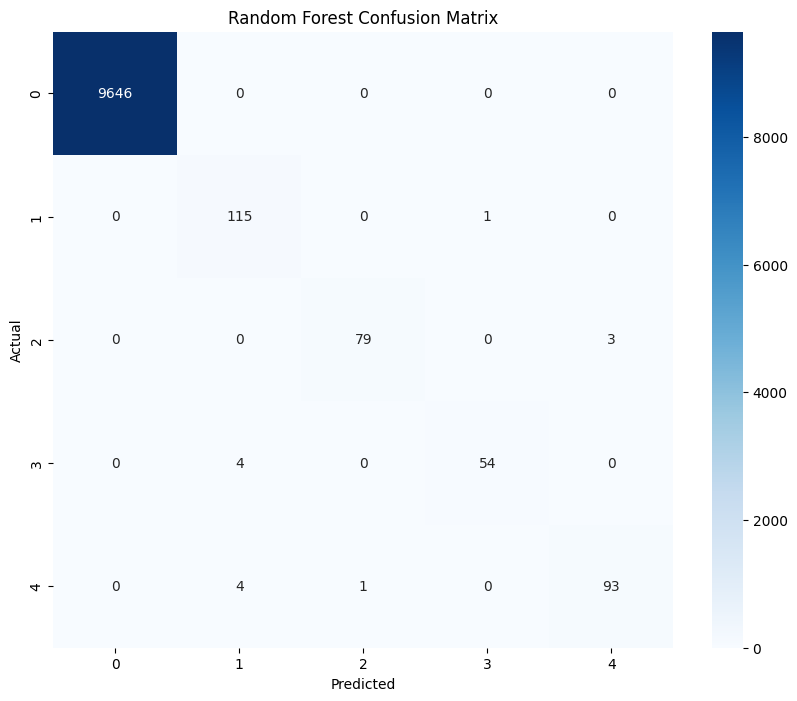

In [ ]:
from sklearn.metrics import confusion_matrix

import matplotlib.pyplot as plt

import seaborn as sns

cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(10,8))

sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues')

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Random Forest Confusion Matrix")

plt.show()

In [ ]:
results = pd.DataFrame({

'Model':['Decision Tree',
         'Random Forest',
         'KNN',
         'SVM',
         'XGBoost'],

'Accuracy':[accuracy_score(y_test,dt_pred),
            accuracy_score(y_test,rf_pred),
            accuracy_score(y_test,knn_pred),
            accuracy_score(y_test,svm_pred),
            accuracy_score(y_test,xgb_pred)]

})

results

,Model,Accuracy
0,Decision Tree,0.9976
1,Random Forest,0.9987
2,KNN,0.9960
3,SVM,0.9973
4,XGBoost,0.9994


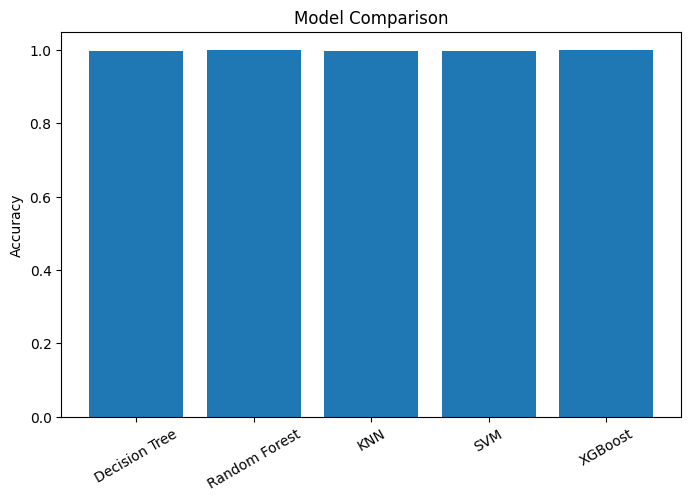

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(results['Model'],
        results['Accuracy'])

plt.xticks(rotation=30)

plt.ylabel("Accuracy")

plt.title("Model Comparison")

plt.show()

In [ ]:
importance = pd.DataFrame({

'Feature':X.columns,

'Importance':rf.feature_importances_

})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

importance.head(15)

,Feature,Importance
18,time_to_fault_min,0.299161
17,efficiency_loss_pct,0.228428
12,vibration_rms,0.101085
9,conversion_rate,0.079192
13,motor_current,0.061218
5,feed_flow_rate,0.050648
6,coolant_flow_rate,0.048956
2,ambient_temp_effect,0.037253
3,reactor_temp,0.028817
1,reactor_id,0.017910


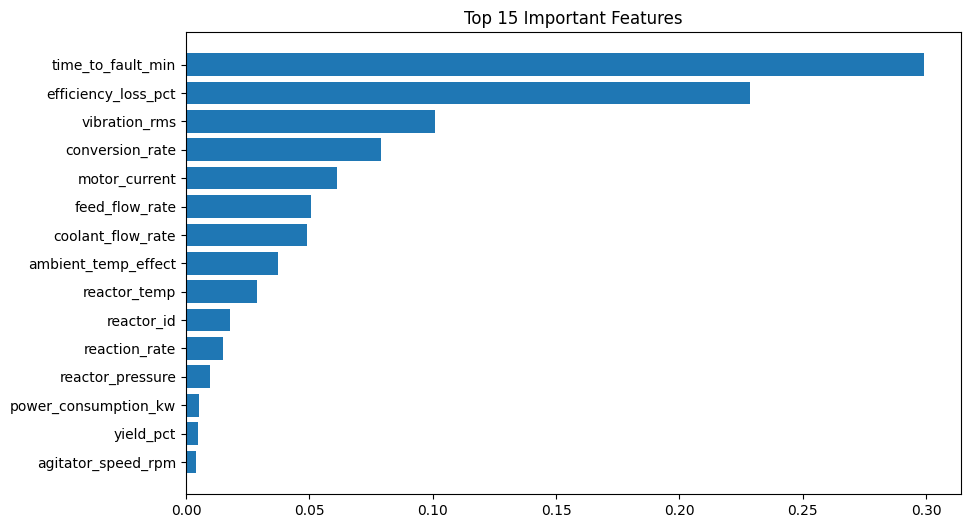

In [ ]:
plt.figure(figsize=(10,6))

plt.barh(
    importance['Feature'][:15],
    importance['Importance'][:15]
)

plt.gca().invert_yaxis()

plt.title("Top 15 Important Features")

plt.show()

In [ ]:
import joblib

joblib.dump(rf,"predictive_maintenance_model.pkl")

print("Model Saved Successfully")

Model Saved Successfully


In [ ]:
from google.colab import files

files.download("predictive_maintenance_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>